# Step 4A — Ego-Oriented BEV Region Test

This notebook validates the conversion

**nuScenes ego pose → local BEV rectangle → global oriented polygon**

before changing the BST hierarchical cover.

It assumes these Step 4A source files already exist:

- `src/bst_bev/query/oriented_region.py`
- `src/bst_bev/nuscenes/pose.py`

The notebook deliberately keeps the BEV size at **60 m × 60 m** (`30 m` in every ego-frame direction) so the result can be compared fairly with the Step 3D axis-aligned baseline.


In [4]:
from pathlib import Path
import sys
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from shapely.geometry import box

from bst_bev.query.polygon_hierarchical import (
    HierarchicalPolygonRegionCover,
)

from bst_bev.maps.hierarchical_bst_map_index import (
    HierarchicalBSTMapIndex,
)

# ------------------------------------------------------------
# Resolve project root whether the notebook is started from
# bst-bev/ or bst-bev/notebooks/.
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

DATAROOT = PROJECT_ROOT / "data" / "nuscenes"

print("Project root:", PROJECT_ROOT)
print("nuScenes root:", DATAROOT)


Project root: /Users/abinavbala/College/Research/BST-BEV
nuScenes root: /Users/abinavbala/College/Research/BST-BEV/data/nuscenes


In [5]:
from nuscenes.nuscenes import NuScenes
from nuscenes.map_expansion.map_api import NuScenesMap

from bst_bev.query.oriented_region import OrientedBEVRegion
from bst_bev.nuscenes.pose import quaternion_to_yaw

MAP_LAYERS = (
    "lane_divider",
    "road_divider",
    "ped_crossing",
)

# Keep the same area as the Step 3D 60 m x 60 m square.
BEV_FRONT_M = 30.0
BEV_BACK_M = 30.0
BEV_LEFT_M = 30.0
BEV_RIGHT_M = 30.0

# Change this to inspect another nuScenes sample.
SAMPLE_INDEX = 0

MIN_ZOOM = 19
TARGET_ZOOM = 24

In [6]:
nusc = NuScenes(
    version="v1.0-mini",
    dataroot=str(DATAROOT),
    verbose=False,
)

print("Scenes:", len(nusc.scene))
print("Samples:", len(nusc.sample))



Scenes: 10
Samples: 404


## Build sample metadata including ego yaw

nuScenes stores the ego rotation as a quaternion `[w, x, y, z]`.  
For each keyframe we extract the global `(x, y)` position and planar yaw.


In [7]:
def get_sample_context(nusc, sample):
    scene = nusc.get(
        "scene",
        sample["scene_token"],
    )

    log = nusc.get(
        "log",
        scene["log_token"],
    )

    location = log["location"]

    lidar = nusc.get(
        "sample_data",
        sample["data"]["LIDAR_TOP"],
    )

    ego_pose = nusc.get(
        "ego_pose",
        lidar["ego_pose_token"],
    )

    ego_x, ego_y, _ = ego_pose["translation"]

    ego_yaw = quaternion_to_yaw(
        ego_pose["rotation"]
    )

    return {
        "sample_token": sample["token"],
        "scene": scene["name"],
        "location": location,
        "ego_x": float(ego_x),
        "ego_y": float(ego_y),
        "ego_yaw": float(ego_yaw),
    }


samples_df = pd.DataFrame(
    get_sample_context(nusc, sample)
    for sample in nusc.sample
)

print("Rows:", len(samples_df))
samples_df.head()


Rows: 404


,sample_token,scene,location,ego_x,ego_y,ego_yaw
0,ca9a282c9e77460f8360f564131a8af5,scene-0061,singapore-onenorth,411.303935,1180.890379,-1.923645
1,39586f9d59004284a7114a68825e8eec,scene-0061,singapore-onenorth,409.743152,1176.676973,-1.917831
2,356d81f38dd9473ba590f39e266f54e5,scene-0061,singapore-onenorth,408.101879,1172.151578,-1.911575
3,e0845f5322254dafadbbed75aaa07969,scene-0061,singapore-onenorth,406.726006,1168.211287,-1.900030
4,c923fe08b2ff4e27975d2bf30934383b,scene-0061,singapore-onenorth,405.409406,1164.354227,-1.895311


In [8]:
locations = sorted(
    samples_df["location"].unique()
)

nusc_maps = {
    location: NuScenesMap(
        dataroot=str(DATAROOT),
        map_name=location,
    )
    for location in locations
}

print("Loaded maps:")
for location in locations:
    print(" -", location)


Loaded maps:
 - boston-seaport
 - singapore-hollandvillage
 - singapore-onenorth
 - singapore-queenstown


## Unit-test the coordinate transform

These simple synthetic checks make sure the rotation convention is correct before using nuScenes data.

- At yaw `0`, ego forward (`+x`) must point along global `+x`.
- At yaw `π/2`, ego forward must point along global `+y`.


In [9]:
test_zero = OrientedBEVRegion(
    center_x=0.0,
    center_y=0.0,
    yaw=0.0,
    front=10.0,
    back=5.0,
    left=3.0,
    right=2.0,
)

assert np.allclose(
    test_zero.local_to_global(10.0, 0.0),
    (10.0, 0.0),
)

test_90 = OrientedBEVRegion(
    center_x=0.0,
    center_y=0.0,
    yaw=math.pi / 2.0,
    front=10.0,
    back=5.0,
    left=3.0,
    right=2.0,
)

assert np.allclose(
    test_90.local_to_global(10.0, 0.0),
    (0.0, 10.0),
    atol=1e-9,
)

assert np.allclose(
    test_90.local_to_global(0.0, 3.0),
    (-3.0, 0.0),
    atol=1e-9,
)

print("Synthetic transform tests passed.")


Synthetic transform tests passed.


## Construct one ego-oriented BEV

The region is centered at the ego position, while the rectangle itself rotates with the vehicle heading.


In [10]:
sample = samples_df.iloc[SAMPLE_INDEX]

bev = OrientedBEVRegion(
    center_x=float(sample["ego_x"]),
    center_y=float(sample["ego_y"]),
    yaw=float(sample["ego_yaw"]),
    front=BEV_FRONT_M,
    back=BEV_BACK_M,
    left=BEV_LEFT_M,
    right=BEV_RIGHT_M,
)

print("Scene:", sample["scene"])
print("Location:", sample["location"])
print("Ego XY:", (bev.center_x, bev.center_y))
print("Yaw [rad]:", bev.yaw)
print("Yaw [deg]:", math.degrees(bev.yaw))
print("Area [m^2]:", bev.area)
print("Polygon valid:", bev.polygon.is_valid)
print()
print("Global corners:")

for i, corner in enumerate(bev.global_corners):
    print(i, corner)

assert math.isclose(
    bev.area,
    3600.0,
    rel_tol=0.0,
    abs_tol=1e-9,
)

assert bev.polygon.is_valid

print()
print("BEV construction checks passed.")


Scene: scene-0061
Location: singapore-onenorth
Ego XY: (411.3039349319818, 1180.8903791765097)
Yaw [rad]: -1.9236454030236563
Yaw [deg]: -110.21676287299779
Area [m^2]: 3600.0
Polygon valid: True

Global corners:
0 (429.08851102240675, 1142.3714376894452)
1 (449.82287641904617, 1198.6749552669346)
2 (393.5193588415569, 1219.4093206635741)
3 (372.78499344491746, 1163.1058030860847)

BEV construction checks passed.


## Visual sanity check

The plot shows:

- the **ego-oriented BEV**,
- the old **axis-aligned 60 m × 60 m square**,
- the ego position,
- a heading arrow.

The heading arrow should point toward the BEV's **front edge**.


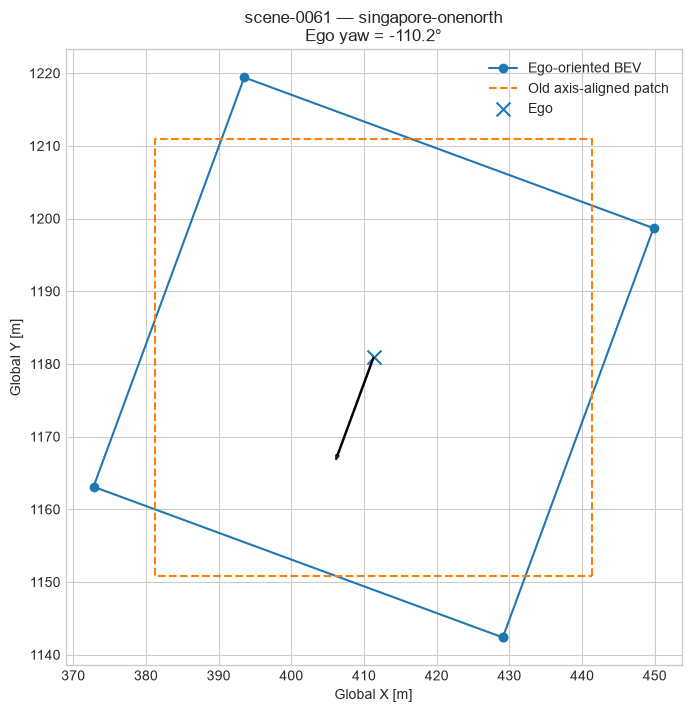

In [11]:
fig, ax = plt.subplots(figsize=(8, 8))

# ------------------------------------------------------------
# Oriented BEV
# ------------------------------------------------------------

oriented_corners = list(bev.global_corners)
oriented_corners.append(oriented_corners[0])

oriented_x = [p[0] for p in oriented_corners]
oriented_y = [p[1] for p in oriented_corners]

ax.plot(
    oriented_x,
    oriented_y,
    marker="o",
    label="Ego-oriented BEV",
)

# ------------------------------------------------------------
# Old axis-aligned Step 3D patch
# ------------------------------------------------------------

old_square = box(
    bev.center_x - 30.0,
    bev.center_y - 30.0,
    bev.center_x + 30.0,
    bev.center_y + 30.0,
)

old_x, old_y = old_square.exterior.xy

ax.plot(
    old_x,
    old_y,
    linestyle="--",
    label="Old axis-aligned patch",
)

# ------------------------------------------------------------
# Ego + heading
# ------------------------------------------------------------

ax.scatter(
    [bev.center_x],
    [bev.center_y],
    marker="x",
    s=100,
    label="Ego",
)

heading_length = 15.0

ax.arrow(
    bev.center_x,
    bev.center_y,
    heading_length * math.cos(bev.yaw),
    heading_length * math.sin(bev.yaw),
    width=0.15,
    length_includes_head=True,
)

ax.set_aspect("equal")
ax.set_xlabel("Global X [m]")
ax.set_ylabel("Global Y [m]")
ax.set_title(
    f"{sample['scene']} — {sample['location']}\n"
    f"Ego yaw = {math.degrees(bev.yaw):.1f}°"
)
ax.legend()

plt.show()


## Polygon-based ground truth

For the oriented query, the old `get_records_in_patch()` square is no longer the correct ground truth.

Here we intersect the oriented polygon with the actual nuScenes map geometry:

- `lane_divider` → line
- `road_divider` → line
- `ped_crossing` → polygon


In [12]:
def get_map_record_geometry(
    nusc_map,
    layer,
    record,
):
    if layer in (
        "lane_divider",
        "road_divider",
    ):
        return nusc_map.extract_line(
            record["line_token"]
        )

    if layer == "ped_crossing":
        return nusc_map.extract_polygon(
            record["polygon_token"]
        )

    raise ValueError(
        f"Unsupported layer: {layer}"
    )


def get_polygon_ground_truth_tokens(
    nusc_map,
    query_polygon,
    map_layers=MAP_LAYERS,
):
    hits = set()

    for layer in map_layers:
        records = getattr(
            nusc_map,
            layer,
        )

        for record in records:
            geometry = get_map_record_geometry(
                nusc_map,
                layer,
                record,
            )

            if geometry.intersects(
                query_polygon
            ):
                hits.add(
                    (
                        layer,
                        record["token"],
                    )
                )

    return hits


In [13]:
test_map = nusc_maps[
    sample["location"]
]

oriented_gt = get_polygon_ground_truth_tokens(
    nusc_map=test_map,
    query_polygon=bev.polygon,
)

print(
    "Oriented polygon ground-truth objects:",
    len(oriented_gt),
)

sorted(oriented_gt)[:20]


Oriented polygon ground-truth objects: 4


[('lane_divider', '3d37fc34-730c-4894-9d8a-6ddbcd2aacbd'),
 ('lane_divider', '425d4a61-7336-4eab-ad58-7615f79d63bb'),
 ('lane_divider', '6b5a4771-79b4-4ddf-b305-5f4f8260b6ac'),
 ('lane_divider', '80fedd56-10ee-4109-8519-56c904230158')]

## Compare against the old axis-aligned ground truth

A difference is **expected** when the ego yaw is not aligned with the global map axes.

Both regions have the same area (`3600 m²`), but they cover different parts of the map.


In [14]:
def get_axis_aligned_ground_truth_tokens(
    nusc_map,
    ego_x,
    ego_y,
    radius=30.0,
):
    patch = (
        ego_x - radius,
        ego_y - radius,
        ego_x + radius,
        ego_y + radius,
    )

    records = nusc_map.get_records_in_patch(
        patch,
        list(MAP_LAYERS),
        mode="intersect",
    )

    return {
        (layer, token)
        for layer, tokens in records.items()
        for token in tokens
    }


old_gt = get_axis_aligned_ground_truth_tokens(
    nusc_map=test_map,
    ego_x=bev.center_x,
    ego_y=bev.center_y,
    radius=30.0,
)

common = old_gt & oriented_gt
old_only = old_gt - oriented_gt
oriented_only = oriented_gt - old_gt

print("Old axis-aligned GT:", len(old_gt))
print("Oriented GT:", len(oriented_gt))
print("Common:", len(common))
print("Only old:", len(old_only))
print("Only oriented:", len(oriented_only))

print()
print("Only old:")
for item in sorted(old_only):
    print(" ", item)

print()
print("Only oriented:")
for item in sorted(oriented_only):
    print(" ", item)


Old axis-aligned GT: 4
Oriented GT: 4
Common: 4
Only old: 0
Only oriented: 0

Only old:

Only oriented:


## Optional: inspect several samples quickly

This is useful for checking that the oriented region behaves sensibly at different headings and locations.


In [15]:
CHECK_INDICES = [0, 50, 100, 200, 300, 403]

rows = []

for idx in CHECK_INDICES:
    row = samples_df.iloc[idx]

    region = OrientedBEVRegion(
        center_x=float(row["ego_x"]),
        center_y=float(row["ego_y"]),
        yaw=float(row["ego_yaw"]),
        front=BEV_FRONT_M,
        back=BEV_BACK_M,
        left=BEV_LEFT_M,
        right=BEV_RIGHT_M,
    )

    gt = get_polygon_ground_truth_tokens(
        nusc_map=nusc_maps[row["location"]],
        query_polygon=region.polygon,
    )

    rows.append({
        "sample_index": idx,
        "scene": row["scene"],
        "location": row["location"],
        "yaw_deg": math.degrees(row["ego_yaw"]),
        "area_m2": region.area,
        "gt_objects": len(gt),
        "polygon_valid": region.polygon.is_valid,
    })

pd.DataFrame(rows)


,sample_index,scene,location,yaw_deg,area_m2,gt_objects,polygon_valid
0,0,scene-0061,singapore-onenorth,-110.216763,3600.0,4,True
1,50,scene-0103,boston-seaport,-39.546665,3600.0,11,True
2,100,scene-0553,boston-seaport,138.310702,3600.0,18,True
3,200,scene-0757,boston-seaport,153.446239,3600.0,13,True
4,300,scene-1077,singapore-hollandvillage,-42.566589,3600.0,9,True
5,403,scene-1100,singapore-hollandvillage,-154.896230,3600.0,10,True


## Step 4A success criteria

This notebook has passed Step 4A when:

1. The synthetic transform assertions pass.
2. Every tested polygon is valid.
3. The BEV area remains `3600 m²`.
4. The heading arrow visually points toward the rectangle's front edge.
5. The polygon-based ground truth returns plausible map primitives.
6. Differences from the old axis-aligned ground truth occur for rotated ego poses and make geometric sense.

Once these checks pass, the next implementation step is **Step 4B: recursively cover this rotated polygon with mixed-resolution BST cells**.


In [16]:
location = sample["location"]

hierarchical_index = (
    HierarchicalBSTMapIndex(
        nusc_map=nusc_maps[
            location
        ],
        location=location,
        min_zoom=MIN_ZOOM,
        max_zoom=TARGET_ZOOM,
        index_spacing_m=1.0,
    )
)

# We do NOT actually need to build the map index yet for
# Step 4B. We only need its spatial encoder.

In [17]:
polygon_coverer = (
    HierarchicalPolygonRegionCover(
        encoder=(
            hierarchical_index.encoder
        ),

        min_zoom=MIN_ZOOM,
        target_zoom=TARGET_ZOOM,

        boundary_step_m=1.0,
    )
)

In [18]:
cover = polygon_coverer.cover(
    bev
)

In [19]:
print(
    "Hierarchical cells:",
    cover.hierarchical_cell_count,
)

print(
    "Equivalent z24 leaves:",
    cover.leaf_equivalent_count,
)

print(
    "Compression:",
    f"{cover.compression_ratio:.2f}x",
)

print(
    "Reduction:",
    f"{100 * cover.reduction_fraction:.2f}%",
)

print(
    "Visited cells:",
    cover.visited_cell_count,
)

print(
    "Interior cells:",
    cover.interior_cell_count,
)

print(
    "Boundary z24 cells:",
    cover.boundary_cell_count,
)

print(
    "Discarded cells:",
    cover.discarded_cell_count,
)

print(
    "Cover time:",
    f"{cover.cover_time_ms:.3f} ms",
)

print()
print(
    "Zoom distribution:"
)

for key, count in sorted(
    cover.zoom_distribution().items()
):
    print(
        key,
        count,
    )

Hierarchical cells: 191
Equivalent z24 leaves: 698
Compression: 3.65x
Reduction: 72.64%
Visited cells: 544
Interior cells: 63
Boundary z24 cells: 128
Discarded cells: 83
Cover time: 43.296 ms

Zoom distribution:
(21, 20) 1
(21, 21) 1
(21, 22) 1
(22, 20) 1
(22, 21) 2
(22, 22) 1
(22, 23) 3
(23, 20) 1
(23, 22) 7
(23, 23) 7
(23, 24) 7
(24, 22) 2
(24, 23) 11
(24, 24) 146


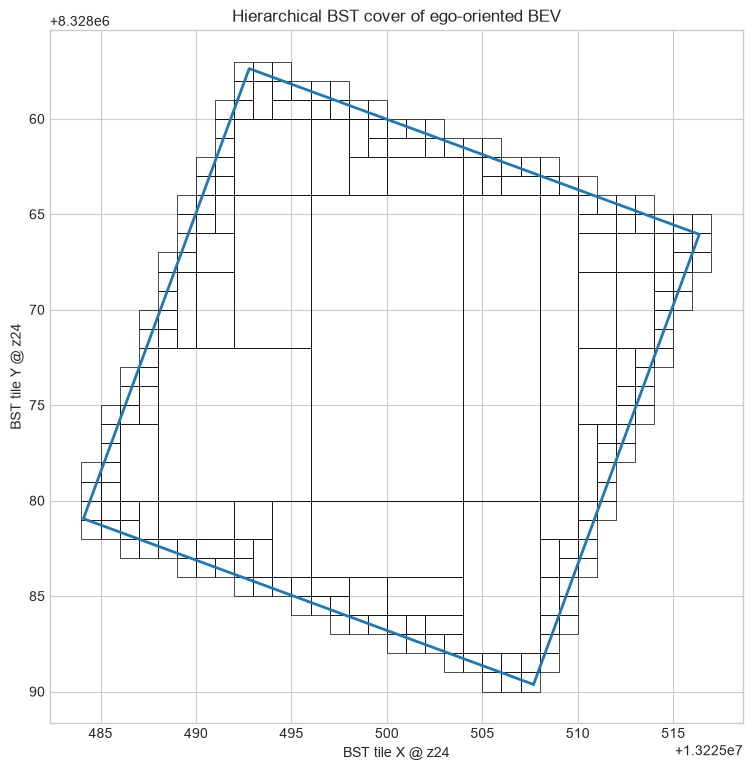

In [20]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


fig, ax = plt.subplots(
    figsize=(9, 9)
)

# Query polygon.
tile_x, tile_y = (
    cover.tile_polygon.exterior.xy
)

ax.plot(
    tile_x,
    tile_y,
    linewidth=2,
    label="Oriented BEV",
)


# Hierarchical BST cells.
for cell in cover.cells:

    (
        x_min,
        y_min,
        x_max,
        y_max,
    ) = polygon_coverer.cell_bounds(
        cell
    )

    rectangle = Rectangle(
        (
            x_min,
            y_min,
        ),

        x_max - x_min,
        y_max - y_min,

        fill=False,
        linewidth=0.5,
    )

    ax.add_patch(
        rectangle
    )


ax.set_aspect(
    "equal"
)

# Web-Mercator tile y increases downward.
ax.invert_yaxis()

ax.set_xlabel(
    "BST tile X @ z24"
)

ax.set_ylabel(
    "BST tile Y @ z24"
)

ax.set_title(
    "Hierarchical BST cover of ego-oriented BEV"
)

plt.show()

In [21]:
from shapely.geometry import box
from shapely.ops import unary_union

In [22]:
cell_polygons = []

for cell in cover.cells:

    bounds = (
        polygon_coverer.cell_bounds(
            cell
        )
    )

    cell_polygons.append(
        box(
            *bounds
        )
    )


cover_union = unary_union(
    cell_polygons
)

In [23]:
uncovered = (
    cover.tile_polygon
    .difference(
        cover_union
    )
)

print(
    "Uncovered area:",
    uncovered.area,
)

print(
    "Cover contains polygon:",
    cover_union.covers(
        cover.tile_polygon
    ),
)

Uncovered area: 0.0
Cover contains polygon: True


In [24]:
polygon_area = (
    cover.tile_polygon.area
)

cover_area = (
    cover_union.area
)

overcoverage_area = (
    cover_area
    - polygon_area
)

overcoverage_ratio = (
    overcoverage_area
    / polygon_area
)

print(
    "Polygon area:",
    polygon_area,
)

print(
    "Cover area:",
    cover_area,
)

print(
    "Over-coverage:",
    f"{100 * overcoverage_ratio:.3f}%",
)

Polygon area: 631.2742218936994
Cover area: 698.0
Over-coverage: 10.570%


In [25]:
results = []

for zoom in [
    23,
    24,
]:

    coverer = (
        HierarchicalPolygonRegionCover(
            encoder=(
                hierarchical_index.encoder
            ),

            min_zoom=19,
            target_zoom=zoom,

            boundary_step_m=1.0,
        )
    )

    result = coverer.cover(
        bev
    )

    results.append({
        "zoom":
            zoom,

        "hierarchical_cells":
            result.hierarchical_cell_count,

        "leaf_equivalent":
            result.leaf_equivalent_count,

        "compression_ratio":
            result.compression_ratio,

        "reduction_fraction":
            result.reduction_fraction,

        "boundary_cells":
            result.boundary_cell_count,

        "visited_cells":
            result.visited_cell_count,

        "cover_time_ms":
            result.cover_time_ms,
    })


pd.DataFrame(
    results
)

,zoom,hierarchical_cells,leaf_equivalent,compression_ratio,reduction_fraction,boundary_cells,visited_cells,cover_time_ms
0,23,89,191,2.146067,0.534031,64,258,20.217791
1,24,191,698,3.654450,0.726361,128,544,42.214458
